# Catching Rare Fraud in Card Transactions
**Author:** Sanika Satoskar · 2026

## 1. The business question
A card issuer wants to flag fraudulent transactions **without annoying good customers**.
Every flagged transaction gets reviewed (or blocked), so the fraud team can only afford a small number of false alarms.

**Question:** Out of every fraud, how many can we catch if we only allow **1 false alarm per 1,000 legitimate transactions** (a 0.1% false-positive rate)?

**Data:** 284,807 real card transactions made by European cardholders over two days (ULB Machine Learning Group, via OpenML).
Only 492 are fraud (0.17%). For privacy, the bank transformed most columns into anonymous features `V1`–`V28`; we also have `Amount`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
from xgboost import XGBClassifier

df = pd.read_parquet("../data/creditcard.parquet")
df["Class"] = df["Class"].astype(int)
print(df.shape)
df["Class"].value_counts()

(284807, 30)


Class
0    284315
1       492
Name: count, dtype: int64

## 2. Why accuracy is the wrong metric
If a model predicted **"not fraud" for everything**, it would be 99.83% accurate and catch **zero** fraud.
So we measure two things instead:
- **Recall:** share of real fraud we catch.
- **False-positive rate (FPR):** share of good transactions we wrongly flag.

We fix FPR at 0.1% (the fraud team's alert budget) and compare models on recall at that level.

Fraud rate: 0.173%
Accuracy of 'always say not fraud': 99.83%


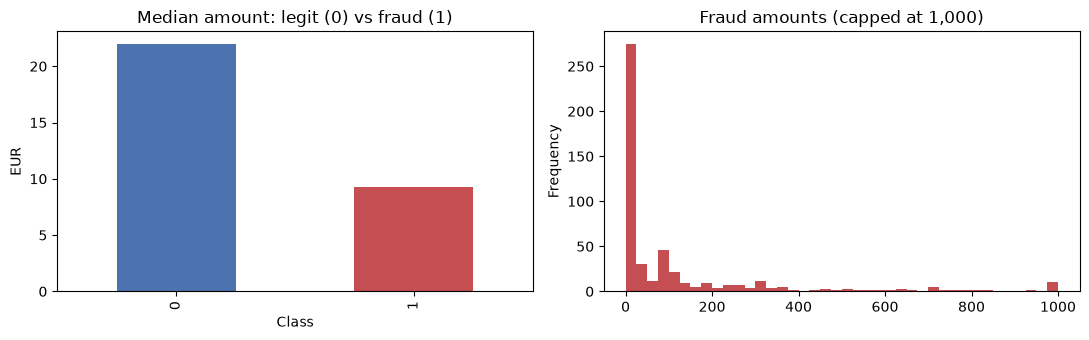

In [2]:
print(f"Fraud rate: {df.Class.mean():.3%}")
print(f"Accuracy of 'always say not fraud': {1-df.Class.mean():.2%}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.groupby("Class")["Amount"].median().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Median amount: legit (0) vs fraud (1)"); ax[0].set_ylabel("EUR")
df[df.Class == 1]["Amount"].clip(upper=1000).plot.hist(bins=40, ax=ax[1], color="#C44E52")
ax[1].set_title("Fraud amounts (capped at 1,000)")
plt.tight_layout(); plt.savefig("../figures/amounts.png", dpi=120); plt.show()

## 3. Honest train / validation / test split
- **Test set (30%)** is locked away until the very end.
- **Validation set (15% of the rest)** is used to *choose the alert threshold*, so the test result is a fair estimate of real performance.
- Splits are **stratified**, so each one keeps the same 0.17% fraud rate.

In [3]:
X, y = df.drop(columns="Class"), df["Class"]
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15, stratify=y_tmp, random_state=42)
for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:>10}: {len(yy):>7,} rows, {yy.sum():>3} fraud")

     train: 169,459 rows, 292 fraud
validation:  29,905 rows,  52 fraud
      test:  85,443 rows, 148 fraud


## 4. Two models
1. **Logistic regression (baseline):** simple, easy to explain, and a common first model at banks.
2. **XGBoost:** gradient-boosted decision trees that can capture interactions (e.g., a *small* amount combined with an unusual `V14` pattern).

Both are told that fraud is rare (`class_weight` / `scale_pos_weight`), so they don't just ignore the minority class.

In [4]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
logit.fit(X_train, y_train)

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=ratio, eval_metric="aucpr",
                    random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
print("trained")

trained


## 5. Pick the alert threshold on validation (FPR = 0.1%)
Each model outputs a fraud *score*. We choose the score cutoff that flags at most 0.1% of good validation transactions, then freeze it.

In [5]:
TARGET_FPR = 0.001
def threshold_at_fpr(model, X, y, target=TARGET_FPR):
    s = model.predict_proba(X)[:, 1]
    legit = np.sort(s[y.values == 0])[::-1]
    k = int(np.floor(target * len(legit)))
    return legit[k] if k < len(legit) else legit[-1]

thr = {"Logistic regression": threshold_at_fpr(logit, X_val, y_val),
       "XGBoost": threshold_at_fpr(xgb, X_val, y_val)}
thr

{'Logistic regression': np.float64(0.9817041957324142),
 'XGBoost': np.float32(0.12023399)}

## 6. Final, one-time evaluation on the locked test set

In [6]:
rows = []
for name, model in [("Logistic regression", logit), ("XGBoost", xgb)]:
    s = model.predict_proba(X_test)[:, 1]
    flag = s > thr[name]
    tp = int((flag & (y_test == 1)).sum()); fp = int((flag & (y_test == 0)).sum())
    fn = int((~flag & (y_test == 1)).sum())
    amt = X_test["Amount"].values
    rows.append({"model": name,
                 "recall": tp / (tp + fn),
                 "false-positive rate": fp / (y_test == 0).sum(),
                 "precision": tp / max(tp + fp, 1),
                 "fraud caught": tp, "fraud missed": fn, "false alarms": fp,
                 "fraud EUR caught": amt[flag & (y_test == 1)].sum(),
                 "fraud EUR total": amt[y_test == 1].sum(),
                 "PR-AUC": average_precision_score(y_test, s)})
results = pd.DataFrame(rows).set_index("model")
results.round(4)

,recall,false-positive rate,precision,fraud caught,fraud missed,false alarms,fraud EUR caught,fraud EUR total,PR-AUC
model,,,,,,,,,
Logistic regression,0.8243,0.0010,0.581,122,26,88,12786.48,19311.89,0.7110
XGBoost,0.8514,0.0013,0.525,126,22,114,12898.30,19311.89,0.8336


The thresholds were picked on validation data, so the test false-positive rate can drift slightly from 0.1%.
For a like-for-like comparison, here is each model's recall at **exactly** 0.1% FPR on the test set (read off the ROC curve):

In [7]:
for name, model in [("Logistic regression", logit), ("XGBoost", xgb)]:
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    print(f"{name}: recall at exactly 0.1% FPR = {np.interp(TARGET_FPR, fpr, tpr):.1%}")

Logistic regression: recall at exactly 0.1% FPR = 81.8%
XGBoost: recall at exactly 0.1% FPR = 85.1%


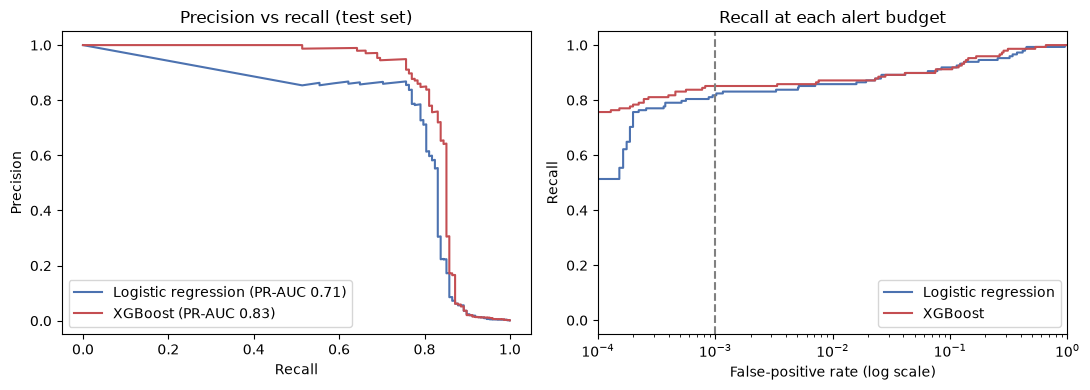

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, model, c in [("Logistic regression", logit, "#4C72B0"), ("XGBoost", xgb, "#C44E52")]:
    s = model.predict_proba(X_test)[:, 1]
    p, r, _ = precision_recall_curve(y_test, s)
    ax[0].plot(r, p, label=f"{name} (PR-AUC {average_precision_score(y_test, s):.2f})", color=c)
    fpr, tpr, _ = roc_curve(y_test, s)
    ax[1].plot(fpr, tpr, label=name, color=c)
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision vs recall (test set)"); ax[0].legend()
ax[1].axvline(TARGET_FPR, ls="--", color="grey"); ax[1].set_xscale("log"); ax[1].set_xlim(1e-4, 1)
ax[1].set_xlabel("False-positive rate (log scale)"); ax[1].set_ylabel("Recall"); ax[1].set_title("Recall at each alert budget"); ax[1].legend()
plt.tight_layout(); plt.savefig("../figures/curves.png", dpi=120); plt.show()

## 7. Which signals drive the XGBoost model?

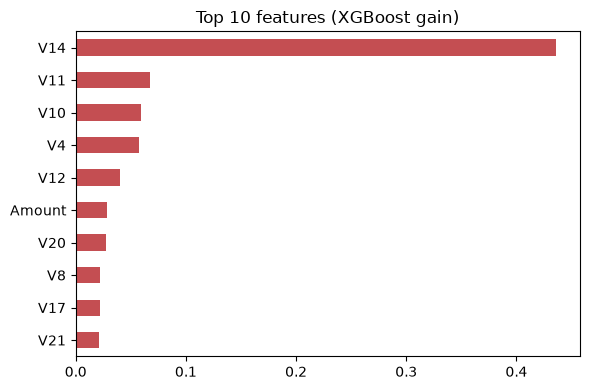

V14       0.436
V11       0.068
V10       0.059
V4        0.057
V12       0.040
Amount    0.029
V20       0.028
V8        0.022
V17       0.022
V21       0.021
dtype: float32

In [9]:
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp[::-1].plot.barh(figsize=(6, 4), color="#C44E52"); plt.title("Top 10 features (XGBoost gain)")
plt.tight_layout(); plt.savefig("../figures/importance.png", dpi=120); plt.show()
imp.round(3)

In [10]:
# Plain-English summary printed from the actual numbers above
L, X_ = results.loc["Logistic regression"], results.loc["XGBoost"]
print(f"At a {TARGET_FPR:.1%} alert budget on unseen test data:")
print(f"- Logistic regression catches {L['recall']:.0%} of fraud ({int(L['fraud caught'])}/{int(L['fraud caught']+L['fraud missed'])}), {int(L['false alarms'])} false alarms")
print(f"- XGBoost catches {X_['recall']:.0%} of fraud ({int(X_['fraud caught'])}/{int(X_['fraud caught']+X_['fraud missed'])}), {int(X_['false alarms'])} false alarms")
print(f"- XGBoost stops EUR {X_['fraud EUR caught']:,.0f} of EUR {X_['fraud EUR total']:,.0f} fraud in the test set ({X_['fraud EUR caught']/X_['fraud EUR total']:.0%})")

At a 0.1% alert budget on unseen test data:
- Logistic regression catches 82% of fraud (122/148), 88 false alarms
- XGBoost catches 85% of fraud (126/148), 114 false alarms
- XGBoost stops EUR 12,898 of EUR 19,312 fraud in the test set (67%)


## 8. Recommendation & limitations
- **Use XGBoost with the validated threshold** if it beats the baseline at the same alert budget. Keep logistic regression as an explainable benchmark.
- The **threshold is a business dial**: a bigger review team can afford a higher FPR and catch more fraud. The recall-vs-FPR chart shows that trade-off.
- **Limitations:** two days of data from one issuer; features are anonymized, so we can't explain *why* `V14` matters in business terms; random (not time-based) split because the OpenML copy has no timestamp column. In production, I'd validate on later time periods and monitor for drift.